# Gráficas del análisis de la temporada ATP 2025

En este notebook me conecto a MongoDB desde Python con pymongo, lanzo algunas de las agregaciones del script y pinto los resultados con matplotlib.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient

cliente = MongoClient("mongodb://localhost:27017")
db = cliente["tenis-2025"]

os.makedirs("graficas", exist_ok=True)

print("Partidos:", db.partidos.count_documents({}))
print("Jugadores:", db.jugadores.count_documents({}))

Partidos: 2944
Jugadores: 455


## Porcentaje de sets que acaban en tiebreak por superficie

La misma agregación que en el script.

In [2]:
fase1 = {"$unwind": "$sets"}
query2 = {"sets.juegos_ganador": {"$ne": None}}
fase2 = {"$match": query2}
es_tiebreak = {"$cond": [{"$ne": ["$sets.tiebreak", None]}, 1, 0]}
query3 = {"_id": "$superficie", "sets": {"$sum": 1}, "tiebreaks": {"$sum": es_tiebreak}}
fase3 = {"$group": query3}
porcentaje = {"$multiply": [{"$divide": ["$tiebreaks", "$sets"]}, 100]}
query4 = {"porcentaje": porcentaje}
fase4 = {"$addFields": query4}
query5 = {"porcentaje": -1}
fase5 = {"$sort": query5}
etapas = [fase1, fase2, fase3, fase4, fase5]

resultado = list(db.partidos.aggregate(etapas))
df_tiebreaks = pd.DataFrame(resultado)
df_tiebreaks

,_id,sets,tiebreaks,porcentaje
0,Hierba,869,193,22.209436
1,Dura,4683,911,19.453342
2,Tierra,1999,293,14.657329


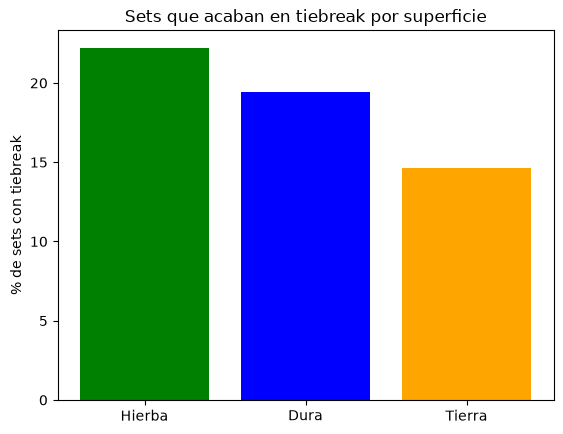

In [3]:
plt.bar(df_tiebreaks["_id"], df_tiebreaks["porcentaje"], color=["green", "blue", "orange"])
plt.ylabel("% de sets con tiebreak")
plt.title("Sets que acaban en tiebreak por superficie")
plt.savefig("graficas/tiebreaks_superficie.png")
plt.show()

## Media de aces por partido según la altura del jugador

In [4]:
jugador1 = {"altura": "$ganador.altura", "aces": "$ganador.estadisticas.aces"}
jugador2 = {"altura": "$perdedor.altura", "aces": "$perdedor.estadisticas.aces"}
query1 = {"con_estadisticas": True}
fase1 = {"$match": query1}
query2 = {"_id": 0, "jugadores": [jugador1, jugador2]}
fase2 = {"$project": query2}
fase3 = {"$unwind": "$jugadores"}
query4 = {"jugadores.altura": {"$ne": None}}
fase4 = {"$match": query4}
fase5 = {
    "$bucket": {
        "groupBy": "$jugadores.altura",
        "boundaries": [165, 175, 180, 185, 190, 195, 200, 215],
        "default": "Otros",
        "output": {
            "partidos": {"$sum": 1},
            "media_aces": {"$avg": "$jugadores.aces"}
        }
    }
}
etapas = [fase1, fase2, fase3, fase4, fase5]

resultado = list(db.partidos.aggregate(etapas))
df_altura = pd.DataFrame(resultado)
df_altura

,_id,partidos,media_aces
0,165,103,2.203883
1,175,355,4.216901
2,180,1543,5.178872
3,185,1659,6.305003
4,190,955,7.456545
5,195,698,9.485673
6,200,182,12.351648


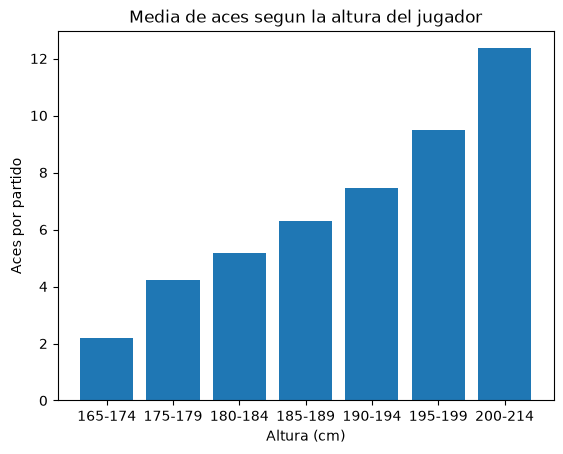

In [5]:
# nombres de los tramos del bucket para el eje x
tramos = ["165-174", "175-179", "180-184", "185-189", "190-194", "195-199", "200-214"]

plt.bar(tramos, df_altura["media_aces"])
plt.xlabel("Altura (cm)")
plt.ylabel("Aces por partido")
plt.title("Media de aces segun la altura del jugador")
plt.savefig("graficas/aces_altura.png")
plt.show()

## Victorias de Alcaraz y Sinner por mes

In [6]:
query1 = {"ganador.nombre": {"$in": ["Carlos Alcaraz", "Jannik Sinner"]}}
fase1 = {"$match": query1}
fase2 = {"$addFields": {"fecha_date": {"$toDate": "$fecha"}}}
grupo = {"jugador": "$ganador.nombre", "mes": {"$month": "$fecha_date"}}
query3 = {"_id": grupo, "victorias": {"$sum": 1}}
fase3 = {"$group": query3}
query4 = {"_id.jugador": 1, "_id.mes": 1}
fase4 = {"$sort": query4}
etapas = [fase1, fase2, fase3, fase4]

resultado = list(db.partidos.aggregate(etapas))

# los meses sin victorias no salen en la agregacion, asi que empiezo con todo a 0
meses = list(range(1, 13))
victorias_alcaraz = [0] * 12
victorias_sinner = [0] * 12

for doc in resultado:
    mes = doc["_id"]["mes"]
    if doc["_id"]["jugador"] == "Carlos Alcaraz":
        victorias_alcaraz[mes - 1] = doc["victorias"]
    else:
        victorias_sinner[mes - 1] = doc["victorias"]

print("Alcaraz:", victorias_alcaraz)
print("Sinner: ", victorias_sinner)

Alcaraz: [4, 7, 4, 9, 13, 11, 0, 13, 6, 0, 4, 0]
Sinner:  [7, 0, 0, 0, 11, 8, 0, 11, 6, 10, 5, 0]


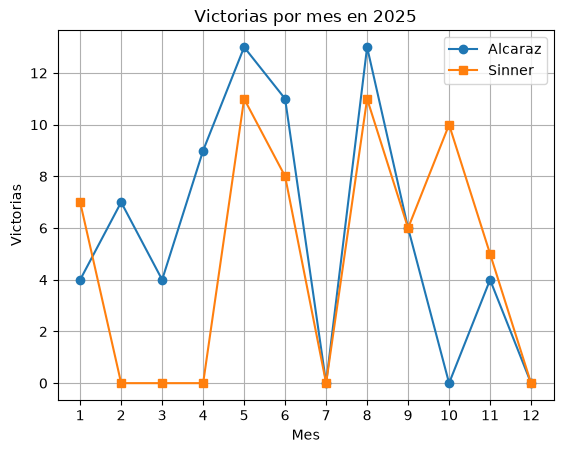

In [7]:
plt.plot(meses, victorias_alcaraz, "o-", label="Alcaraz")
plt.plot(meses, victorias_sinner, "s-", label="Sinner")
plt.xticks(meses)
plt.xlabel("Mes")
plt.ylabel("Victorias")
plt.title("Victorias por mes en 2025")
plt.legend()
plt.grid(True)
plt.savefig("graficas/victorias_mes.png")
plt.show()

## Mejores porcentajes de victoria

Leo la colección `jugadores` que guardé con `$out`.

In [8]:
query = {"partidos": {"$gte": 40}}
cursor = db.jugadores.find(query).sort("porcentaje", -1).limit(10)
df_jugadores = pd.DataFrame(list(cursor))
df_jugadores

,_id,pais,partidos,victorias,porcentaje
0,Jannik Sinner,ITA,64,58,90.625000
1,Carlos Alcaraz,ESP,80,71,88.750000
2,Novak Djokovic,SRB,50,39,78.000000
3,Jack Draper,GBR,40,30,75.000000
4,Alex de Minaur,AUS,81,57,70.370370
5,Alexander Zverev,GER,83,58,69.879518
6,Taylor Fritz,USA,76,53,69.736842
7,Casper Ruud,NOR,56,39,69.642857
8,Felix Auger-Aliassime,CAN,75,51,68.000000
9,Tommy Paul,USA,43,29,67.441860


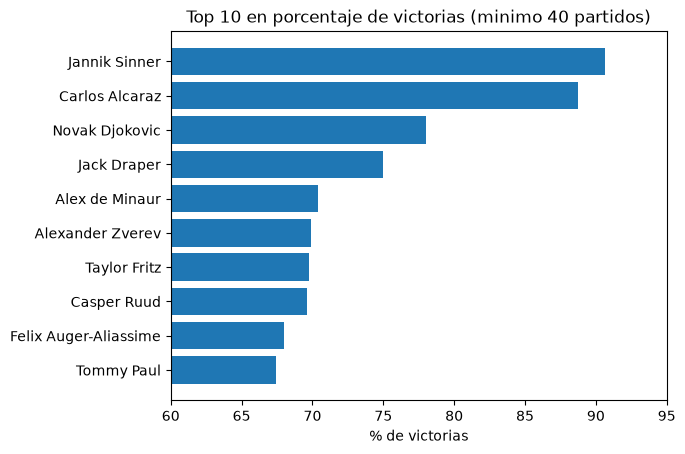

In [9]:
# ordeno de menor a mayor para que en la grafica horizontal el mejor quede arriba
df_jugadores = df_jugadores.sort_values("porcentaje")

plt.barh(df_jugadores["_id"], df_jugadores["porcentaje"])
plt.xlim(60, 95)
plt.xlabel("% de victorias")
plt.title("Top 10 en porcentaje de victorias (minimo 40 partidos)")
plt.savefig("graficas/top10_porcentaje.png", bbox_inches="tight")
plt.show()